# FinGuard AI — Exploratory Data Analysis

## 1. Business Context

Financial institutions process large volumes of transactions and must identify potentially fraudulent activity while minimizing disruption to legitimate customers.

Fraud detection presents several challenges:

- **Class imbalance:** Fraudulent transactions typically represent a small proportion of total activity.
- **False positives:** Incorrectly flagging legitimate transactions can negatively affect customer experience and increase investigation costs.
- **False negatives:** Undetected fraudulent transactions may result in financial losses.
- **Transaction relationships:** Suspicious behavior may emerge from connections between accounts rather than isolated transactions.

**Business Problem:** Identify potentially fraudulent financial transactions and support risk-based investigation decisions.

**Machine Learning Task:** Binary classification — is a transaction fraudulent (`isFraud = 1`) or legitimate (`isFraud = 0`)?

**Project Objective:** Develop an end-to-end fraud intelligence platform combining machine learning, transaction network analysis, model explainability, and an interactive investigation dashboard.

---

## 2. Dataset Description

**Source:** [PaySim — Synthetic Financial Datasets for Fraud Detection](https://www.kaggle.com/datasets/ealaxi/paysim1)

**Dataset:** Synthetic mobile money transactions generated using the PaySim simulator.

**Target Variable:** `isFraud`

**Unit of Analysis:** Individual financial transaction.

### Dataset Variables

| Variable | Type | Description |
|---|---|---|
| `step` | int | Simulation time step; each step represents one hour |
| `type` | str | Transaction category: CASH_IN, CASH_OUT, DEBIT, PAYMENT or TRANSFER |
| `amount` | float | Transaction amount |
| `nameOrig` | str | Originating account identifier |
| `oldbalanceOrg` | float | Origin account balance before the transaction |
| `newbalanceOrig` | float | Origin account balance after the transaction |
| `nameDest` | str | Destination account identifier |
| `oldbalanceDest` | float | Destination account balance before the transaction |
| `newbalanceDest` | float | Destination account balance after the transaction |
| `isFraud` | int | Fraud label: 1 = fraudulent, 0 = legitimate |
| `isFlaggedFraud` | int | Indicator of a transaction flagged by the simulator's rule-based mechanism |

### Research Objectives

1. Quantify fraud prevalence and evaluate class imbalance.
2. Identify transaction characteristics associated with fraudulent activity.
3. Investigate temporal patterns and relationships between accounts.
4. Assess data quality and potential information leakage.
5. Translate exploratory findings into feature engineering and modeling decisions.

### Dataset Limitations

PaySim contains simulated rather than real-world banking transactions. Consequently, identified fraud patterns may reflect simulator-specific assumptions.

Additionally, post-transaction balances and existing fraud indicators require careful assessment before inclusion as predictive features.

The analysis will distinguish exploratory associations from validated predictive performance.

In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Project configuration
DATA_PATH = Path("../data/raw/paysim.csv")

# Visual identity
COLORS = {
    "navy": "#14263D",
    "blue": "#4C86A8",
    "cyan": "#59C3C3",
    "light": "#EAF4F7",
}

sns.set_theme(style="whitegrid")

# Read a small preview
df_preview = pd.read_csv(DATA_PATH, nrows=100_000)

# Count all transactions without loading the full dataset
with DATA_PATH.open("r", encoding="utf-8") as file:
    total_rows = sum(1 for _ in file) - 1

print(f"Total transactions: {total_rows:,}")
print(f"Total features: {df_preview.shape[1]}")
print(f"Preview observations: {len(df_preview):,}")

display(df_preview.head())
display(
    df_preview.dtypes.to_frame(name="Data Type")
)


Total transactions: 6,362,620
Total features: 11
Preview observations: 100,000


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


,Data Type
step,int64
type,str
amount,float64
nameOrig,str
oldbalanceOrg,float64
newbalanceOrig,float64
nameDest,str
oldbalanceDest,float64
newbalanceDest,float64
isFraud,int64


### Findings — Initial Dataset Inspection

- **Dataset size:** 6,362,620 transactions × 11 variables. The dataset is substantially larger than a typical introductory classification dataset, requiring memory-conscious data processing.

- **Feature types:** The dataset contains numerical transaction attributes, a categorical transaction type, account identifiers, and binary fraud-related indicators.

- **Target variable:** `isFraud` is the binary classification target, distinguishing fraudulent transactions (`1`) from legitimate transactions (`0`).

- **Account identifiers:** `nameOrig` and `nameDest` identify transaction participants. Although these identifiers are not directly suitable as ordinary numerical features, they may support account-level behavioral analysis and graph-based fraud detection.

- **Potential data leakage:** `newbalanceOrig` and `newbalanceDest` represent post-transaction balances and may not be available at the time of fraud prediction. Their inclusion as predictive features requires careful assessment.

- **Existing fraud flag:** `isFlaggedFraud` reflects a rule-based signal from the simulator. Its availability at prediction time and its relationship with the target must be investigated before deciding whether to include it.

**Decisions:**
1. Use memory-efficient data loading for exploratory analysis.
2. Preserve account identifiers for future network analysis.
3. Assess feature availability at prediction time before defining the modeling dataset.
4. Perform full-dataset quality checks before drawing conclusions about completeness and integrity.

## 3. Target Analysis — Fraud Distribution

The target variable `isFraud` indicates whether a transaction is fraudulent (`1`) or legitimate (`0`).

The objective of this analysis is to quantify fraud prevalence and determine the degree of class imbalance.

Understanding the target distribution is essential for selecting appropriate evaluation metrics, establishing meaningful baselines, and designing a reliable fraud detection strategy.

To avoid potential bias from the initial chronological preview, fraud prevalence is calculated across the complete dataset.

In [9]:

# Calculate fraud distribution across the full dataset
fraud_counts = pd.Series(
    {0: 0, 1: 0},
    dtype="int64"
)

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["isFraud"],
    chunksize=250_000
):
    counts = chunk["isFraud"].value_counts()
    fraud_counts = fraud_counts.add(
        counts, fill_value=0
    ).astype("int64")

fraud_summary = pd.DataFrame({
    "Count": fraud_counts,
    "Percentage": (
        fraud_counts / fraud_counts.sum() * 100
    ).round(4)
})

fraud_summary.index = [
    "Legitimate",
    "Fraud"
]

display(fraud_summary)

,Count,Percentage
Legitimate,6354407,99.8709
Fraud,8213,0.1291


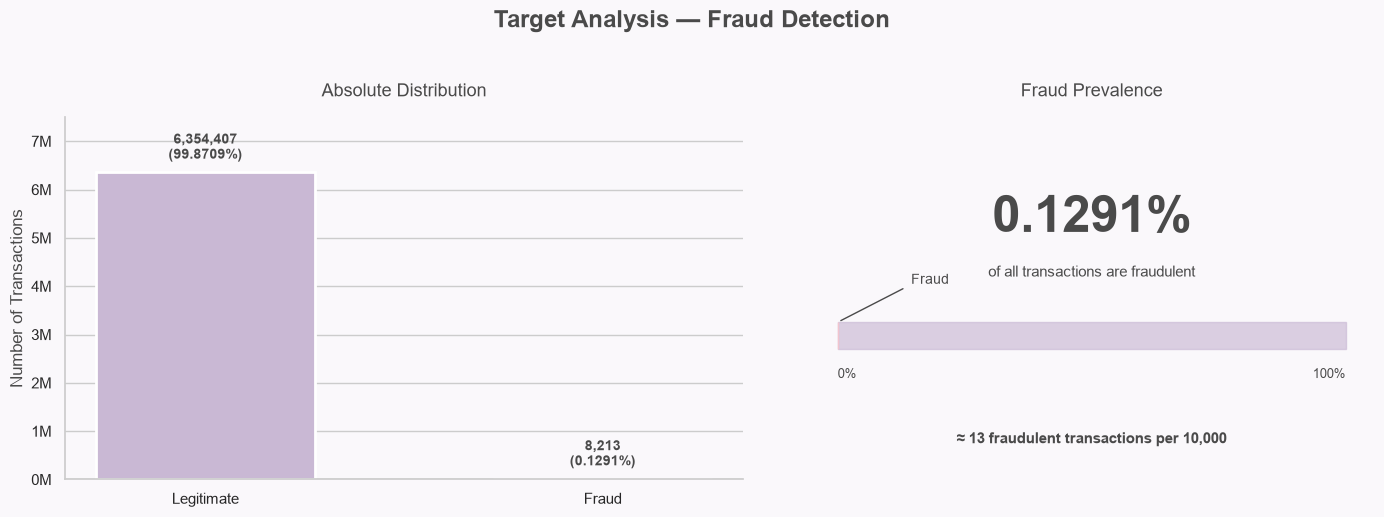

In [14]:

# Target Analysis — Fraud Distribution

from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Rectangle

labels = fraud_summary.index
counts = fraud_summary["Count"]
percentages = fraud_summary["Percentage"]

fraud_rate = percentages.loc["Fraud"]
fraud_count = counts.loc["Fraud"]
total_count = counts.sum()

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    facecolor=COLORS["background"],
    gridspec_kw={"width_ratios": [1.2, 1]}
)

fig.suptitle(
    "Target Analysis — Fraud Detection",
    fontsize=17,
    fontweight="bold",
    color=COLORS["text"],
    y=1.03
)

for ax in axes:
    ax.set_facecolor(COLORS["background"])

# 1. Absolute Distribution
ax = axes[0]

bars = ax.bar(
    labels,
    counts,
    color=[COLORS["lavender"], COLORS["pink"]],
    width=0.55,
    edgecolor="white",
    linewidth=2
)

ax.set_title("Absolute Distribution", fontsize=13, pad=15)
ax.set_ylabel("Number of Transactions")
ax.set_ylim(0, counts.max() * 1.18)

# Format y-axis in millions
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1e6:g}M")
)

for bar, count, pct in zip(bars, counts, percentages):
    ax.annotate(
        f"{count:,}\n({pct:.4f}%)",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=COLORS["text"]
    )

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

# 2. Fraud Prevalence Indicator
ax = axes[1]
ax.set_title("Fraud Prevalence", fontsize=13, pad=15)

ax.set_xlim(0, 100)
ax.set_ylim(0, 1)
ax.axis("off")

# Main percentage
ax.text(
    50, 0.72,
    f"{fraud_rate:.4f}%",
    ha="center",
    va="center",
    fontsize=37,
    fontweight="bold",
    color=COLORS["text"]
)

ax.text(
    50, 0.56,
    "of all transactions are fraudulent",
    ha="center",
    fontsize=11,
    color=COLORS["text"]
)

# Proportional bar (0–100%)
bar_y = 0.36
bar_height = 0.075

ax.add_patch(
    Rectangle(
        (5, bar_y),
        90, bar_height,
        color=COLORS["lavender"],
        alpha=0.65
    )
)

ax.add_patch(
    Rectangle(
        (5, bar_y),
        90 * fraud_rate / 100,
        bar_height,
        color=COLORS["pink"]
    )
)

# Make the tiny fraud segment visible with a marker
ax.annotate(
    "",
    xy=(5 + 90 * fraud_rate / 100, bar_y + bar_height),
    xytext=(17, bar_y + 0.17),
    arrowprops={
        "arrowstyle": "-",
        "color": COLORS["text"],
        "lw": 1
    }
)

ax.text(
    18, bar_y + 0.18,
    "Fraud",
    fontsize=10,
    color=COLORS["text"]
)

ax.text(
    5, 0.28,
    "0%",
    fontsize=9,
    color=COLORS["text"]
)

ax.text(
    95, 0.28,
    "100%",
    ha="right",
    fontsize=9,
    color=COLORS["text"]
)

# Business-friendly interpretation
fraud_per_10k = fraud_count / total_count * 10_000

ax.text(
    50, 0.10,
    f"≈ {fraud_per_10k:.0f} fraudulent transactions per 10,000",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color=COLORS["text"]
)

plt.tight_layout(w_pad=4)
plt.show()


### Findings — Target Distribution

- **Extreme class imbalance:** Only **8,213 out of 6,362,620 transactions (0.1291%)** are fraudulent, while 99.8709% are legitimate. This corresponds to approximately **774 legitimate transactions for every fraudulent transaction**.

- **Misleading accuracy:** A naive classifier predicting every transaction as legitimate would achieve **99.87% accuracy**, despite failing to detect any fraudulent activity.

- **Fraud detection challenge:** The extremely low fraud prevalence makes minority-class detection difficult. Even a small false positive rate could generate a substantial number of unnecessary alerts.

- **Business impact:** False negatives represent undetected fraud, while false positives may disrupt legitimate transactions and increase investigation costs. Both types of errors must be considered when evaluating model performance.

**Decisions:**
- Use **PR-AUC (Average Precision)** as a primary evaluation metric, complemented by precision, recall, and F1-score.
- Evaluate class weighting and other imbalance-handling strategies during model development.
- Optimize the classification threshold based on the trade-off between fraud detection and false alerts.
- Apply chronological data splitting to assess performance on future transactions and reduce temporal leakage.

**Conclusion:** Fraud detection performance cannot be evaluated reliably using accuracy alone. The modeling strategy must prioritize minority-class detection while maintaining an operationally manageable false positive rate.

## 4. Data Quality & Transaction Integrity

Before investigating fraud patterns, we assess the dataset's structural integrity and identify potential data quality issues that could affect downstream modeling.

The analysis focuses on missing values, duplicate records, and numerical consistency.

### 4.1 Missing Values Analysis

Missing values may introduce bias, reduce the effective sample size, or require additional preprocessing.

We examine the number and percentage of missing values across all features using the complete dataset.

To minimize memory consumption, the analysis is performed using chunk-based processing.

In [17]:

# 4.1 Missing Values Analysis

missing_counts = pd.Series(
    0,
    index=df_preview.columns,
    dtype="int64"
)

for chunk in pd.read_csv(
    DATA_PATH,
    chunksize=250_000
):
    missing_counts += chunk.isna().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing (%)": (
        missing_counts / total_rows * 100
    ).round(4)
})

missing_summary = missing_summary.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_summary)

print(f"Total missing values: {missing_counts.sum():,}")


,Missing Count,Missing (%)
step,0,0.0
type,0,0.0
amount,0,0.0
nameOrig,0,0.0
oldbalanceOrg,0,0.0
newbalanceOrig,0,0.0
nameDest,0,0.0
oldbalanceDest,0,0.0
newbalanceDest,0,0.0
isFraud,0,0.0


Total missing values: 0


### Findings — Missing Values

- **Complete dataset:** No missing values were identified across the 6,362,620 transactions and 11 variables. All features exhibit a missing value rate of 0%.

- **Synthetic data characteristics:** The absence of missing values is consistent with the dataset's simulated nature, where transaction attributes are generated under predefined rules rather than collected from multiple real-world banking systems.

- **Potential hidden data quality issues:** The absence of explicit null values does not guarantee data integrity. Zero balances, inconsistent account movements, and simulator-specific conventions may still require investigation.

**Decision:** No missing-value imputation is required based on the current assessment. Further data quality checks will focus on transaction duplication, numerical consistency, and the interpretation of zero balances.

### 4.2 Duplicate Transactions Analysis

Duplicate records may distort transaction frequencies, bias statistical estimates, and potentially lead to overly optimistic model evaluation if identical observations appear in both training and test sets.

We investigate fully identical records across all dataset columns.

Because the dataset contains more than six million transactions, the duplicate check is performed using DuckDB, which supports SQL-based analysis directly on CSV files.

Duplicate records will not be removed automatically. Any detected duplicates will require further investigation to determine whether they represent data quality issues or repeated transaction activity.

In [18]:

# 4.2 Duplicate Transactions Analysis

import duckdb

con = duckdb.connect()

csv_path = DATA_PATH.resolve().as_posix()

duplicate_summary = con.execute(
    """
    WITH transaction_counts AS (
        SELECT
            *,
            COUNT(*) AS occurrence_count
        FROM read_csv_auto(?)
        GROUP BY ALL
    )
    SELECT
        COALESCE(
            SUM(occurrence_count - 1), 0
        ) AS duplicate_rows,
        COALESCE(
            SUM(
                CASE
                    WHEN occurrence_count > 1 THEN 1
                    ELSE 0
                END
            ), 0
        ) AS duplicated_groups
    FROM transaction_counts
    """,
    [csv_path]
).df()

duplicate_rows = int(
    duplicate_summary.loc[0, "duplicate_rows"]
)

duplicate_groups = int(
    duplicate_summary.loc[0, "duplicated_groups"]
)

print(f"Total transactions: {total_rows:,}")
print(f"Exact duplicate rows: {duplicate_rows:,}")
print(f"Duplicated groups: {duplicate_groups:,}")
print(
    f"Duplicate rate: "
    f"{duplicate_rows / total_rows * 100:.4f}%"
)

con.close()


Total transactions: 6,362,620
Exact duplicate rows: 0
Duplicated groups: 0
Duplicate rate: 0.0000%


### Findings — Duplicate Transactions

- **No exact duplicates:** No fully identical records were detected among the 6,362,620 transactions when comparing all 11 dataset columns.

- **Dataset uniqueness:** The exact duplicate rate is **0.0000%**, indicating that every transaction has a unique combination of recorded attributes.

- **Synthetic data characteristics:** This result is consistent with the structured nature of the simulated dataset. However, the absence of exact duplicates does not rule out repeated or suspicious transaction patterns involving the same accounts.

**Decision:** No duplicate removal is required. All transactions will be retained for subsequent analysis and modeling.

**Conclusion:** The dataset passes the initial missing-value and exact-duplicate checks. Further validation is necessary to assess numerical consistency, account balances, and potential simulator-specific anomalies.


### 4.3 Transaction Balance Consistency

Financial transactions are expected to follow accounting relationships between transaction amounts and account balances.

For outgoing transactions, the expected origin balance is:

$$
\text{Expected Balance} = \text{Old Balance} - \text{Amount}
$$

For incoming cash transactions (`CASH_IN`), the expected origin balance is:

$$
\text{Expected Balance} = \text{Old Balance} + \text{Amount}
$$

We compare these expected values with the recorded post-transaction balances to identify potential inconsistencies.

The analysis is performed across the complete dataset and summarized by transaction type.

A small numerical tolerance is applied to avoid classifying floating-point rounding differences as inconsistencies.

**Important:** Balance inconsistencies are descriptive data quality indicators, not necessarily errors or evidence of fraud. Their interpretation depends on transaction semantics and simulator-specific conventions.


In [19]:

# 4.3 Origin Balance Consistency

import numpy as np

balance_columns = [
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig"
]

balance_results = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=balance_columns,
    chunksize=250_000
):
    # CASH_IN increases the origin account balance.
    # Other transaction types are treated as outflows.
    expected_balance = np.where(
        chunk["type"].eq("CASH_IN"),
        chunk["oldbalanceOrg"] + chunk["amount"],
        chunk["oldbalanceOrg"] - chunk["amount"]
    )

    # Absolute difference between expected and recorded balances
    balance_error = np.abs(
        chunk["newbalanceOrig"].to_numpy()
        - expected_balance
    )

    chunk["balance_inconsistent"] = balance_error > 0.01

    summary = (
        chunk.groupby("type")["balance_inconsistent"]
        .agg(["sum", "count"])
        .reset_index()
    )

    balance_results.append(summary)

# Combine summaries from all chunks
balance_summary = (
    pd.concat(balance_results)
    .groupby("type", as_index=False)
    .agg({
        "sum": "sum",
        "count": "sum"
    })
)

balance_summary = balance_summary.rename(
    columns={
        "sum": "Inconsistent Transactions",
        "count": "Total Transactions"
    }
)

balance_summary["Inconsistency (%)"] = (
    balance_summary["Inconsistent Transactions"]
    / balance_summary["Total Transactions"]
    * 100
).round(4)

balance_summary = balance_summary.sort_values(
    "Inconsistency (%)",
    ascending=False
)

display(balance_summary)

print(
    "Overall origin balance inconsistency rate: "
    f"{balance_summary['Inconsistent Transactions'].sum() / total_rows * 100:.4f}%"
)


,type,Inconsistent Transactions,Total Transactions,Inconsistency (%)
4,TRANSFER,508782,532909,95.4726
1,CASH_OUT,1991269,2237500,88.9953
3,PAYMENT,1165894,2151495,54.1899
2,DEBIT,12462,41432,30.0782
0,CASH_IN,101096,1399284,7.2248


Overall origin balance inconsistency rate: 59.4017%


### Findings — Transaction Balance Consistency

- **Substantial balance discrepancies:** Under the simplified accounting rules, inconsistencies are particularly frequent in `TRANSFER` (95.47%) and `CASH_OUT` (89.00%) transactions.

- **Transaction-type differences:** `PAYMENT` (54.19%) and `DEBIT` (30.08%) exhibit moderate-to-high inconsistency rates, while `CASH_IN` (7.22%) shows considerably greater consistency with the expected balance relationship.

- **Interpretation limitations:** These discrepancies do not necessarily indicate corrupted data or fraudulent activity. They may reflect insufficient account balances, transaction-specific behavior, or conventions used by the PaySim simulator.

- **Further investigation required:** The high discrepancy rates warrant additional analysis of zero balances, transaction amounts, and the relationship between balance inconsistencies and fraud labels.

**Decisions:**
- Retain all transactions without modifying recorded balances.
- Investigate the distribution of zero balances and balance discrepancies by transaction type.
- Treat post-transaction balances as potentially unavailable at prediction time and exclude them from any pre-transaction fraud detection model unless their availability can be justified.

**Conclusion:** Although the dataset contains no missing values or exact duplicates, its recorded balances do not consistently follow simplified accounting expectations. Further investigation is necessary before interpreting these discrepancies as data quality problems or predictive fraud signals.


### 4.4 Zero Balance Investigation

Although no explicit missing values were detected, zero balances may reveal important transaction patterns or simulator-specific conventions.

We examine the prevalence of zero values across four account balance variables:

- `oldbalanceOrg`: Origin account balance before the transaction.
- `newbalanceOrig`: Origin account balance after the transaction.
- `oldbalanceDest`: Destination account balance before the transaction.
- `newbalanceDest`: Destination account balance after the transaction.

The analysis is conducted on the complete dataset and segmented by transaction type.

**Objective:** Determine whether zero balances are concentrated in specific transaction categories and identify patterns that may help explain the accounting discrepancies observed in Section 4.3.

Zero balances are not automatically treated as missing or invalid values.


In [20]:

# 4.4 Zero Balance Investigation

balance_cols = [
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

zero_balance_results = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["type"] + balance_cols,
    chunksize=250_000
):
    zero_flags = chunk[balance_cols].eq(0)
    zero_flags["type"] = chunk["type"]

    summary = zero_flags.groupby("type").agg(
        {col: ["sum", "count"] for col in balance_cols}
    )

    zero_balance_results.append(summary)

# Aggregate counts across all chunks
zero_counts = pd.concat(zero_balance_results).groupby(
    level=0
).sum()

# Calculate percentage of zero balances per transaction type
zero_balance_summary = pd.DataFrame(index=zero_counts.index)

for col in balance_cols:
    zero_balance_summary[col] = (
        zero_counts[(col, "sum")]
        / zero_counts[(col, "count")]
        * 100
    ).round(2)

zero_balance_summary.index.name = "Transaction Type"

display(
    zero_balance_summary.style
    .format("{:.2f}%")
    .background_gradient(cmap="RdPu")
)


,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
Transaction Type,,,,
CASH_IN,0.96%,0.00%,11.69%,19.36%
CASH_OUT,45.85%,88.72%,14.49%,0.51%
DEBIT,14.86%,28.45%,0.00%,1.13%
PAYMENT,35.99%,51.18%,100.00%,100.00%
TRANSFER,53.06%,95.97%,12.22%,0.97%


### Findings — Zero Balance Investigation

- **High prevalence of zero ending balances:** `TRANSFER` (95.97%) and `CASH_OUT` (88.72%) exhibit exceptionally high rates of zero `newbalanceOrig` values. These rates closely resemble the accounting discrepancy rates observed in Section 4.3.

- **Transaction-specific balance patterns:** Zero balances are not uniformly distributed across transaction types. `PAYMENT` and `DEBIT` also exhibit substantial proportions of zero ending balances, while `CASH_IN` shows virtually none.

- **Merchant account conventions:** All `PAYMENT` transactions have zero values for both `oldbalanceDest` and `newbalanceDest`. This suggests that destination balances for this transaction category are not represented in the same way as balances for other transaction types.

- **Potential explanation for balance discrepancies:** The similarity between zero ending-balance rates and accounting inconsistency rates suggests that recorded zero balances may contribute substantially to the discrepancies identified earlier. However, transaction-level validation is required to establish this relationship.

**Decisions:**
- Preserve zero balances as recorded rather than treating them as missing values.
- Investigate the overlap between zero ending balances and accounting discrepancies.
- Interpret balance-related features in the context of transaction type.
- Assess feature availability at prediction time before using balance variables in fraud detection models.

**Conclusion:** Zero balances exhibit strong transaction-specific patterns, highlighting important structural characteristics of the PaySim dataset. These patterns require careful interpretation and may help explain why simplified accounting relationships do not consistently hold.


### 4.5 Zero Balances and Accounting Discrepancies

The previous analyses revealed similar rates of zero ending balances and accounting discrepancies, particularly for `TRANSFER` and `CASH_OUT` transactions.

However, similar aggregate percentages do not establish whether both conditions occur in the same records.

To investigate this relationship, we calculate:

- **P(Zero Balance | Inconsistency):** Percentage of inconsistent transactions with a zero ending origin balance.
- **P(Inconsistency | Zero Balance):** Percentage of zero-ending-balance transactions that exhibit an accounting discrepancy.

The analysis is performed on the complete dataset and segmented by transaction type.

**Objective:** Determine whether zero ending balances account for a substantial proportion of the observed accounting discrepancies.


In [21]:

# 4.5 Zero Balances & Accounting Discrepancies

overlap_results = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=[
        "type",
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig"
    ],
    chunksize=250_000
):
    expected_balance = np.where(
        chunk["type"].eq("CASH_IN"),
        chunk["oldbalanceOrg"] + chunk["amount"],
        chunk["oldbalanceOrg"] - chunk["amount"]
    )

    inconsistent = (
        np.abs(
            chunk["newbalanceOrig"].to_numpy()
            - expected_balance
        ) > 0.01
    )

    zero_balance = chunk["newbalanceOrig"].eq(0).to_numpy()

    chunk["inconsistent"] = inconsistent
    chunk["zero_balance"] = zero_balance
    chunk["both"] = inconsistent & zero_balance

    summary = (
        chunk.groupby("type")[
            ["inconsistent", "zero_balance", "both"]
        ]
        .sum()
    )

    overlap_results.append(summary)

overlap_counts = (
    pd.concat(overlap_results)
    .groupby(level=0)
    .sum()
)

overlap_summary = pd.DataFrame({
    "P(Zero | Inconsistent) (%)": (
        overlap_counts["both"]
        / overlap_counts["inconsistent"].replace(0, np.nan)
        * 100
    ),
    "P(Inconsistent | Zero) (%)": (
        overlap_counts["both"]
        / overlap_counts["zero_balance"].replace(0, np.nan)
        * 100
    )
}).round(2)

overlap_summary.index.name = "Transaction Type"

display(
    overlap_summary.style
    .format("{:.2f}%", na_rep="N/A")
    .background_gradient(cmap="RdPu")
)


,P(Zero | Inconsistent) (%),P(Inconsistent | Zero) (%)
Transaction Type,,
CASH_IN,0.00%,N/A
CASH_OUT,99.49%,99.79%
DEBIT,94.58%,100.00%
PAYMENT,94.44%,100.00%
TRANSFER,99.75%,99.23%


### Findings — Zero Balances and Accounting Discrepancies

- **Strong transaction-level association:** Zero ending origin balances are present in 99.75% of inconsistent `TRANSFER` transactions and 99.49% of inconsistent `CASH_OUT` transactions.

- **High conditional inconsistency rates:** Among transactions with zero ending origin balances, 99.23% of `TRANSFER` and 99.79% of `CASH_OUT` transactions exhibit discrepancies under the simplified accounting rules.

- **Similar patterns across other outflow categories:** `PAYMENT` and `DEBIT` also show a strong overlap between zero ending balances and accounting discrepancies.

- **Distinct CASH_IN behavior:** No inconsistent `CASH_IN` transactions have an exactly zero ending origin balance. The conditional inconsistency rate among zero-ending-balance transactions is undefined because no such records were observed.

- **Interpretation:** These results establish a strong association between recorded zero ending balances and accounting discrepancies. However, they do not establish that zero balances are erroneous, nor do they explain the simulator's underlying accounting conventions.

**Decisions:**
- Preserve the original balance values without automatic correction or imputation.
- Avoid treating accounting discrepancies as confirmed data errors.
- Account for transaction-type differences when analyzing financial behavior.
- Exclude post-transaction balances from pre-authorization fraud models unless their availability at prediction time is established.

**Conclusion:** The majority of accounting discrepancies in outgoing transaction categories coincide with zero ending origin balances. This suggests that zero-balance patterns are central to understanding the observed inconsistencies, although their underlying causes remain unverified.

### Data Quality — Summary and Preprocessing Decisions

| Assessment | Key Finding | Preprocessing Decision |
|---|---|---|
| Missing values | No missing values across 6,362,620 transactions | No missing-value imputation required |
| Exact duplicates | No fully identical records detected | No duplicate removal required |
| Balance consistency | High discrepancy rates, particularly for `TRANSFER` and `CASH_OUT` | Preserve original values; investigate accounting conventions |
| Zero balances | Strong transaction-specific patterns, including 100% zero destination balances for `PAYMENT` | Retain zeros; avoid interpreting them as missing values |
| Discrepancy overlap | Most outgoing transaction discrepancies coincide with zero ending origin balances | Do not automatically classify discrepancies as data errors |
| Feature availability | Post-transaction balances may be unavailable before authorization | Assess temporal availability before feature selection |

**Overall conclusion:** The PaySim dataset passes the initial completeness and exact-duplicate checks but exhibits important balance-related patterns that require careful interpretation. These findings will inform subsequent feature engineering, leakage prevention, and model development.

**Next step:** Investigate transaction behavior and fraud patterns across transaction types, amounts, and time.


## 5. Transaction Type Analysis

Transaction categories may exhibit different fraud patterns, reflecting variations in transaction behavior and financial risk.

This section investigates how fraudulent activity is distributed across transaction types and whether certain categories exhibit disproportionately high fraud rates.

### 5.1 Fraud Distribution by Transaction Type

We analyze three complementary metrics:

- **Transaction volume:** Total number of transactions within each category.
- **Fraud count:** Number of fraudulent transactions within each category.
- **Fraud rate:** Percentage of fraudulent transactions relative to the total volume of that category.

The fraud rate is calculated as:

$$
\text{Fraud Rate (\%)} =
\frac{\text{Fraudulent Transactions}}{\text{Total Transactions}}
\times 100
$$

The analysis is performed on the complete dataset to ensure that rare fraudulent events are accurately represented.

**Objective:** Identify transaction categories associated with fraudulent activity and distinguish absolute fraud volume from relative fraud prevalence.


In [22]:

# 5.1 Fraud Distribution by Transaction Type

transaction_results = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["type", "isFraud"],
    chunksize=250_000
):
    summary = (
        chunk.groupby("type")["isFraud"]
        .agg(["count", "sum"])
        .reset_index()
    )

    transaction_results.append(summary)

# Aggregate results across the complete dataset
transaction_summary = (
    pd.concat(transaction_results)
    .groupby("type", as_index=False)
    .agg({
        "count": "sum",
        "sum": "sum"
    })
)

transaction_summary = transaction_summary.rename(
    columns={
        "type": "Transaction Type",
        "count": "Total Transactions",
        "sum": "Fraudulent Transactions"
    }
)

transaction_summary["Fraud Rate (%)"] = (
    transaction_summary["Fraudulent Transactions"]
    / transaction_summary["Total Transactions"]
    * 100
).round(4)

transaction_summary = transaction_summary.sort_values(
    "Fraud Rate (%)",
    ascending=False
).reset_index(drop=True)

display(
    transaction_summary.style
    .format({
        "Total Transactions": "{:,}",
        "Fraudulent Transactions": "{:,}",
        "Fraud Rate (%)": "{:.4f}%"
    })
    .background_gradient(
        subset=["Fraud Rate (%)"],
        cmap="RdPu"
    )
)

print(
    "Total fraudulent transactions: "
    f"{transaction_summary['Fraudulent Transactions'].sum():,}"
)


,Transaction Type,Total Transactions,Fraudulent Transactions,Fraud Rate (%)
0,TRANSFER,"532,909","4,097",0.7688%
1,CASH_OUT,"2,237,500","4,116",0.1840%
2,CASH_IN,"1,399,284",0,0.0000%
3,DEBIT,"41,432",0,0.0000%
4,PAYMENT,"2,151,495",0,0.0000%


Total fraudulent transactions: 8,213


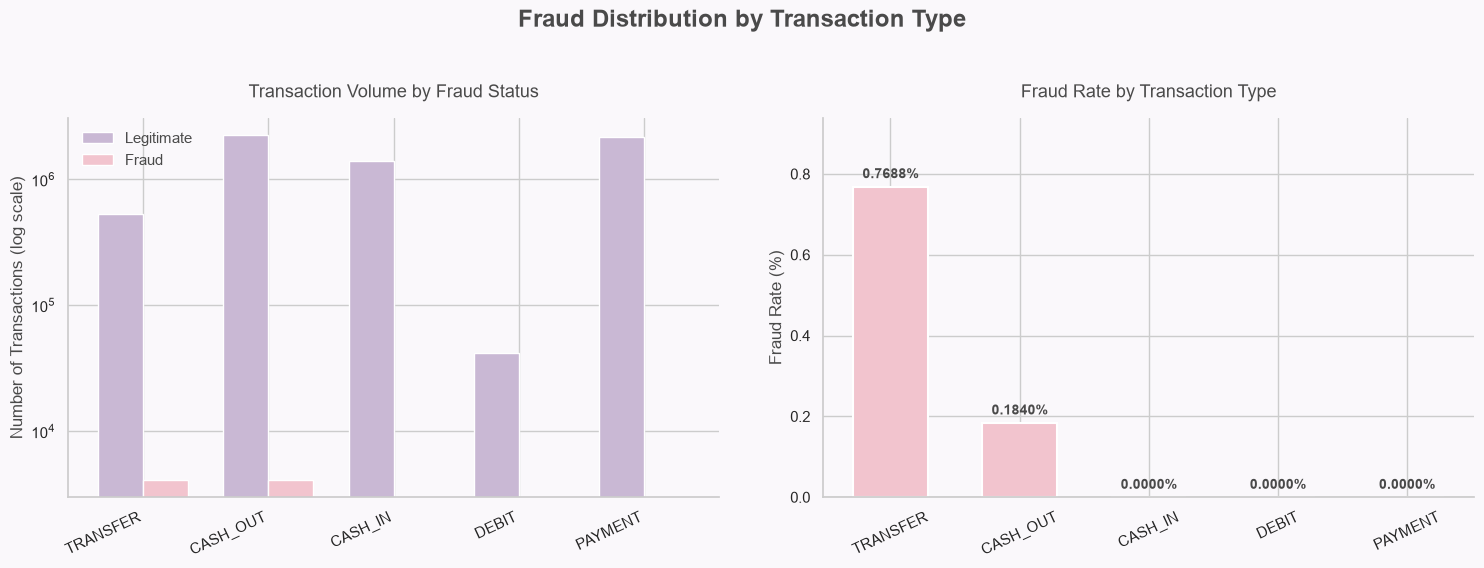

In [23]:

# 5.1 Fraud Distribution by Transaction Type — Visualization

plot_data = transaction_summary.copy()

plot_data["Legitimate Transactions"] = (
    plot_data["Total Transactions"]
    - plot_data["Fraudulent Transactions"]
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5.5),
    facecolor=COLORS["background"]
)

fig.suptitle(
    "Fraud Distribution by Transaction Type",
    fontsize=17,
    fontweight="bold",
    color=COLORS["text"],
    y=1.03
)

types = plot_data["Transaction Type"]
x = np.arange(len(types))
width = 0.36

for ax in axes:
    ax.set_facecolor(COLORS["background"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)

# 1. Transaction volume by fraud status
axes[0].bar(
    x - width / 2,
    plot_data["Legitimate Transactions"],
    width,
    label="Legitimate",
    color=COLORS["lavender"]
)

axes[0].bar(
    x + width / 2,
    plot_data["Fraudulent Transactions"],
    width,
    label="Fraud",
    color=COLORS["pink"]
)

axes[0].set_title(
    "Transaction Volume by Fraud Status",
    fontsize=13,
    pad=15
)

axes[0].set_ylabel("Number of Transactions (log scale)")
axes[0].set_yscale("log")
axes[0].set_xticks(x)
axes[0].set_xticklabels(types, rotation=25, ha="right")
axes[0].legend(frameon=False)

# 2. Fraud rate by transaction type
bars = axes[1].bar(
    types,
    plot_data["Fraud Rate (%)"],
    color=COLORS["pink"],
    width=0.58,
    edgecolor="white",
    linewidth=1.5
)

axes[1].set_title(
    "Fraud Rate by Transaction Type",
    fontsize=13,
    pad=15
)

axes[1].set_ylabel("Fraud Rate (%)")
axes[1].set_ylim(
    0,
    plot_data["Fraud Rate (%)"].max() * 1.22
)
axes[1].tick_params(axis="x", rotation=25)

for bar, rate in zip(
    bars,
    plot_data["Fraud Rate (%)"]
):
    axes[1].annotate(
        f"{rate:.4f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=COLORS["text"]
    )

plt.tight_layout(w_pad=3)
plt.show()


### Findings — Fraud Distribution by Transaction Type

- **Fraud concentration:** All 8,213 fraudulent transactions are associated with only two transaction categories: `TRANSFER` (4,097 cases) and `CASH_OUT` (4,116 cases). No fraudulent transactions are labeled in `CASH_IN`, `DEBIT`, or `PAYMENT`.

- **Highest relative fraud prevalence:** `TRANSFER` exhibits the highest fraud rate at **0.7688%**, approximately **4.18 times** the rate observed in `CASH_OUT` (0.1840%).

- **Volume versus risk:** Although `CASH_OUT` accounts for slightly more fraudulent transactions in absolute terms, its substantially larger transaction volume results in a lower fraud rate than `TRANSFER`.

- **Transaction type as a potential predictive feature:** Fraud labels are strongly associated with transaction category in this dataset. However, this relationship reflects the PaySim data-generating process and may not generalize to real-world banking systems.

**Decisions:**
- Retain transaction type as a candidate categorical feature for fraud prediction.
- Use transaction-type stratification when interpreting model performance and error patterns.
- Investigate transaction amounts and account behavior separately for `TRANSFER` and `CASH_OUT`.
- Avoid assuming that transaction categories with zero observed fraud are inherently risk-free outside this dataset.

**Conclusion:** Fraud in PaySim is concentrated exclusively in transfer and cash-out transactions, with transfers exhibiting substantially higher relative fraud prevalence. Transaction type is therefore an important variable for subsequent exploratory analysis and feature engineering.


### 5.2 Transaction Amount Analysis

Transaction amounts may provide valuable information for identifying unusual financial activity and distinguishing fraudulent transactions from legitimate behavior.

We investigate the distribution of transaction amounts across fraud classes, focusing on the two transaction categories in which fraud occurs: `TRANSFER` and `CASH_OUT`.

The analysis considers:

- **Mean and median:** To compare average transaction values and typical transaction amounts.
- **Standard deviation:** To assess variability in transaction amounts.
- **Interquartile range (IQR):** To describe the central 50% of transaction values.
- **Maximum values:** To identify potentially extreme transactions.

Because financial amounts are often highly skewed, median values and quartiles are considered alongside the mean.

**Objective:** Determine whether fraudulent transactions exhibit distinct amount patterns and whether these patterns vary by transaction type.


In [24]:

# 5.2 Transaction Amount Analysis

import duckdb

con = duckdb.connect()

amount_summary = con.execute(
    """
    SELECT
        type AS transaction_type,
        isFraud AS is_fraud,
        COUNT(*) AS transaction_count,
        AVG(amount) AS mean_amount,
        MEDIAN(amount) AS median_amount,
        STDDEV_SAMP(amount) AS std_amount,
        QUANTILE_CONT(amount, 0.25) AS q25,
        QUANTILE_CONT(amount, 0.75) AS q75,
        MAX(amount) AS max_amount
    FROM read_csv_auto(?)
    WHERE type IN ('TRANSFER', 'CASH_OUT')
    GROUP BY type, isFraud
    ORDER BY type, isFraud
    """,
    [DATA_PATH.resolve().as_posix()]
).df()

con.close()

display(
    amount_summary.style
    .format({
        "transaction_count": "{:,.0f}",
        "mean_amount": "{:,.2f}",
        "median_amount": "{:,.2f}",
        "std_amount": "{:,.2f}",
        "q25": "{:,.2f}",
        "q75": "{:,.2f}",
        "max_amount": "{:,.2f}"
    })
    .background_gradient(
        subset=["median_amount"],
        cmap="RdPu"
    )
)


,transaction_type,is_fraud,transaction_count,mean_amount,median_amount,std_amount,q25,q75,max_amount
0,CASH_OUT,0,"2,233,384","173,917.16","146,946.56","131,222.24","72,627.69","246,181.18","2,847,566.62"
1,CASH_OUT,1,"4,116","1,455,102.59","435,516.91","2,393,841.79","125,464.45","1,500,761.03","10,000,000.00"
2,TRANSFER,0,"528,812","906,229.01","486,521.91","1,874,155.26","216,570.77","972,733.64","92,445,516.64"
3,TRANSFER,1,"4,097","1,480,891.67","445,705.76","2,414,890.38","128,417.96","1,534,985.07","10,000,000.00"


#### Transaction Amount Distribution — Logarithmic Transformation

The descriptive statistics reveal substantial differences between mean and median transaction amounts, indicating positively skewed distributions with high-value observations.

Visualizing these amounts on their original scale may compress the central distributions, making comparisons between legitimate and fraudulent transactions difficult.

To improve interpretability, we apply a **base-10 logarithmic transformation**:

$$
x_{\text{transformed}} = \log_{10}(1 + x)
$$

where \(x\) represents the original transaction amount.

This transformation:

- **Reduces the visual influence of extreme values**, allowing the central distributions to be compared more clearly.
- **Preserves the ordering of observations**, since the logarithmic function is strictly increasing.
- **Accommodates zero-valued transactions** through the addition of 1, avoiding the undefined logarithm of zero.

The resulting boxplots compare legitimate and fraudulent transactions separately for `TRANSFER` and `CASH_OUT`.

**Note:** The transformation is applied exclusively for visualization. Original transaction amounts remain unchanged, and the annotated median values are calculated from the complete dataset. The boxplots use a deterministic sample of legitimate transactions and all fraudulent transactions.

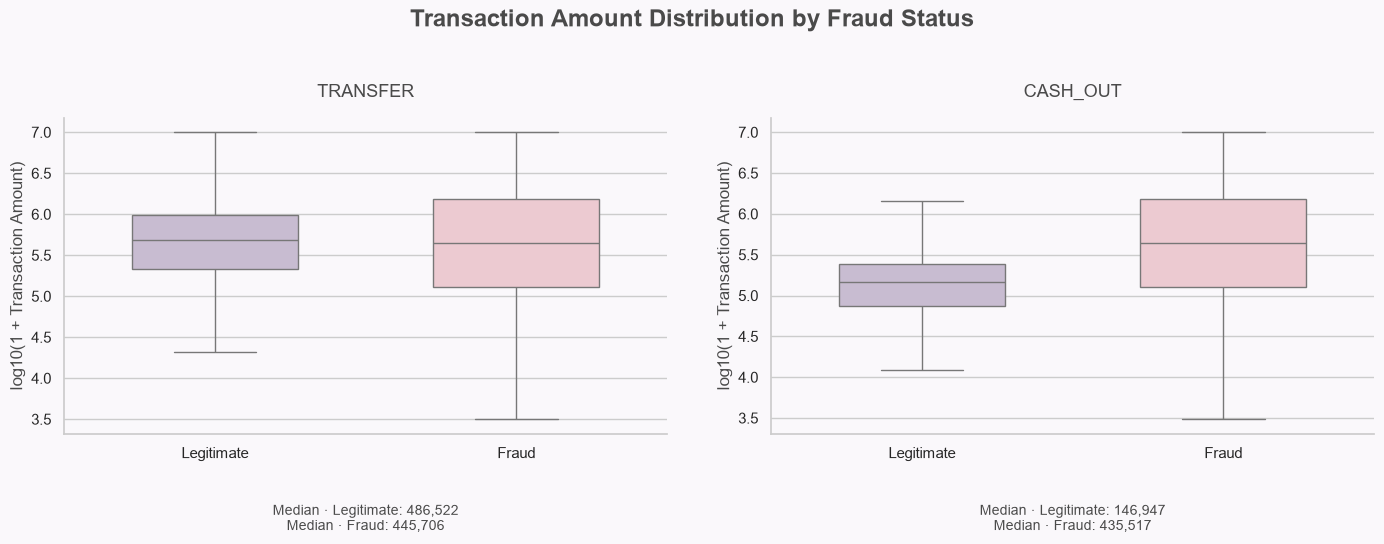

In [26]:


# 5.2 Transaction Amount Distributions — Visualization

import duckdb

con = duckdb.connect()

# Reproducible sample: all fraud + 4% of legitimate transactions
amount_plot = con.execute(
    """
    SELECT type, isFraud, amount
    FROM read_csv_auto(?)
    WHERE type IN ('TRANSFER', 'CASH_OUT')
      AND (
          isFraud = 1
          OR hash(
              nameOrig, nameDest, step,
              amount, oldbalanceOrg, newbalanceOrig
          ) % 100 < 4
      )
    """,
    [DATA_PATH.resolve().as_posix()]
).df()

con.close()

amount_plot["Fraud Status"] = amount_plot["isFraud"].map({
    0: "Legitimate",
    1: "Fraud"
})

# Log transformation handles zero amounts
amount_plot["Log Amount"] = np.log10(
    1 + amount_plot["amount"]
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5),
    facecolor=COLORS["background"]
)

fig.suptitle(
    "Transaction Amount Distribution by Fraud Status",
    fontsize=17,
    fontweight="bold",
    color=COLORS["text"],
    y=1.03
)

for ax, transaction_type in zip(
    axes, ["TRANSFER", "CASH_OUT"]
):
    subset = amount_plot[
        amount_plot["type"] == transaction_type
    ]

    sns.boxplot(
        data=subset,
        x="Fraud Status",
        y="Log Amount",
        order=["Legitimate", "Fraud"],
        hue="Fraud Status",
        hue_order=["Legitimate", "Fraud"],
        palette=PALETTE,
        dodge=False,
        legend=False,
        showfliers=False,
        width=0.55,
        ax=ax
    )

    ax.set_title(
        transaction_type,
        fontsize=13,
        pad=15
    )
    ax.set_xlabel("")
    ax.set_ylabel("log10(1 + Transaction Amount)")
    ax.set_facecolor(COLORS["background"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", visible=False)

    # Show original-scale median values from the full dataset
    medians = amount_summary[
        amount_summary["transaction_type"] == transaction_type
    ].set_index("is_fraud")["median_amount"]

    median_text = (
        f"Median · Legitimate: {medians.loc[0]:,.0f}\n"
        f"Median · Fraud: {medians.loc[1]:,.0f}"
    )

    ax.text(
        0.5, -0.22,
        median_text,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=10,
        color=COLORS["text"]
    )

plt.tight_layout(w_pad=3)
plt.show()


### Findings — Transaction Amount Analysis

- **Higher fraudulent cash-out amounts:** Fraudulent `CASH_OUT` transactions have a median amount of 435,516.91, approximately 2.96 times the legitimate median of 146,946.56.

- **Different transfer behavior:** Fraudulent `TRANSFER` transactions have a slightly lower median amount (445,705.76) than legitimate transfers (486,521.91), despite exhibiting a higher mean. This indicates that the relationship between transaction amount and fraud differs across transaction types.

- **Right-skewed distributions:** Fraudulent transactions in both categories exhibit means substantially higher than their medians, suggesting strong right-skewness and the influence of high-value transactions.

- **Potential simulator constraints:** The maximum fraudulent transaction amount is exactly 10,000,000 in both categories, while legitimate transfers can exceed this value. This pattern warrants further investigation before drawing conclusions about fraud-related amount limits.

**Decisions:**
- Retain `amount` as a candidate predictive feature.
- Investigate transaction amount in combination with transaction type rather than assuming a uniform relationship with fraud.
- Consider logarithmic transformations or robust scaling during feature engineering.
- Preserve extreme values until their validity and predictive relevance have been assessed.

**Conclusion:** Transaction amount distributions differ meaningfully between fraudulent and legitimate activity, but the relationship is transaction-type dependent. Amount alone is unlikely to provide a universally reliable fraud detection rule.


### 5.3 Temporal Fraud Analysis

Financial fraud may exhibit temporal patterns, including variations in transaction activity and fraud prevalence over time.

In the PaySim dataset, `step` represents the elapsed simulation time in hourly increments. It does not correspond to an actual calendar date or a verified hour of the day.

We investigate:

- **Transaction volume over time:** How overall transaction activity evolves throughout the simulation.
- **Fraud frequency over time:** How fraudulent transactions are distributed across simulation periods.
- **Temporal fraud prevalence:** Whether the proportion of fraudulent transactions varies over time.

To improve interpretability and reduce noise from individual simulation hours, transactions are aggregated into consecutive 24-hour periods.

The fraud rate for each period is calculated as:

$$
\text{Fraud Rate (\%)} =
\frac{\text{Fraudulent Transactions in Period}}
{\text{Total Transactions in Period}}
\times 100
$$

**Objective:** Identify temporal patterns and assess their implications for model evaluation, particularly the use of chronological training, validation, and test splits.


In [27]:

# 5.3 Temporal Fraud Analysis

temporal_results = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["step", "isFraud"],
    chunksize=250_000
):
    # Consecutive 24-hour simulation periods
    chunk["period"] = ((chunk["step"] - 1) // 24) + 1

    summary = (
        chunk.groupby("period")["isFraud"]
        .agg(["count", "sum"])
        .reset_index()
    )

    temporal_results.append(summary)

# Aggregate results from all chunks
temporal_summary = (
    pd.concat(temporal_results)
    .groupby("period", as_index=False)
    .agg({
        "count": "sum",
        "sum": "sum"
    })
)

temporal_summary = temporal_summary.rename(
    columns={
        "period": "Simulation Day",
        "count": "Total Transactions",
        "sum": "Fraudulent Transactions"
    }
)

temporal_summary["Fraud Rate (%)"] = (
    temporal_summary["Fraudulent Transactions"]
    / temporal_summary["Total Transactions"]
    * 100
).round(4)

temporal_summary = temporal_summary.sort_values(
    "Simulation Day"
).reset_index(drop=True)

display(temporal_summary)

print(
    f"Simulation periods: {len(temporal_summary)}"
)

print(
    f"First simulation day: "
    f"{temporal_summary['Simulation Day'].min()}"
)

print(
    f"Last simulation day: "
    f"{temporal_summary['Simulation Day'].max()}"
)

print(
    f"Total fraudulent transactions: "
    f"{temporal_summary['Fraudulent Transactions'].sum():,}"
)


,Simulation Day,Total Transactions,Fraudulent Transactions,Fraud Rate (%)
0,1,574255,271,0.0472
1,2,455238,309,0.0679
2,3,1070,310,28.9720
3,4,28240,262,0.9278
4,5,9789,252,2.5743
5,6,441005,228,0.0517
6,7,420583,272,0.0647
7,8,449637,278,0.0618
8,9,417919,255,0.0610
9,10,392945,282,0.0718


Simulation periods: 31
First simulation day: 1
Last simulation day: 31
Total fraudulent transactions: 8,213


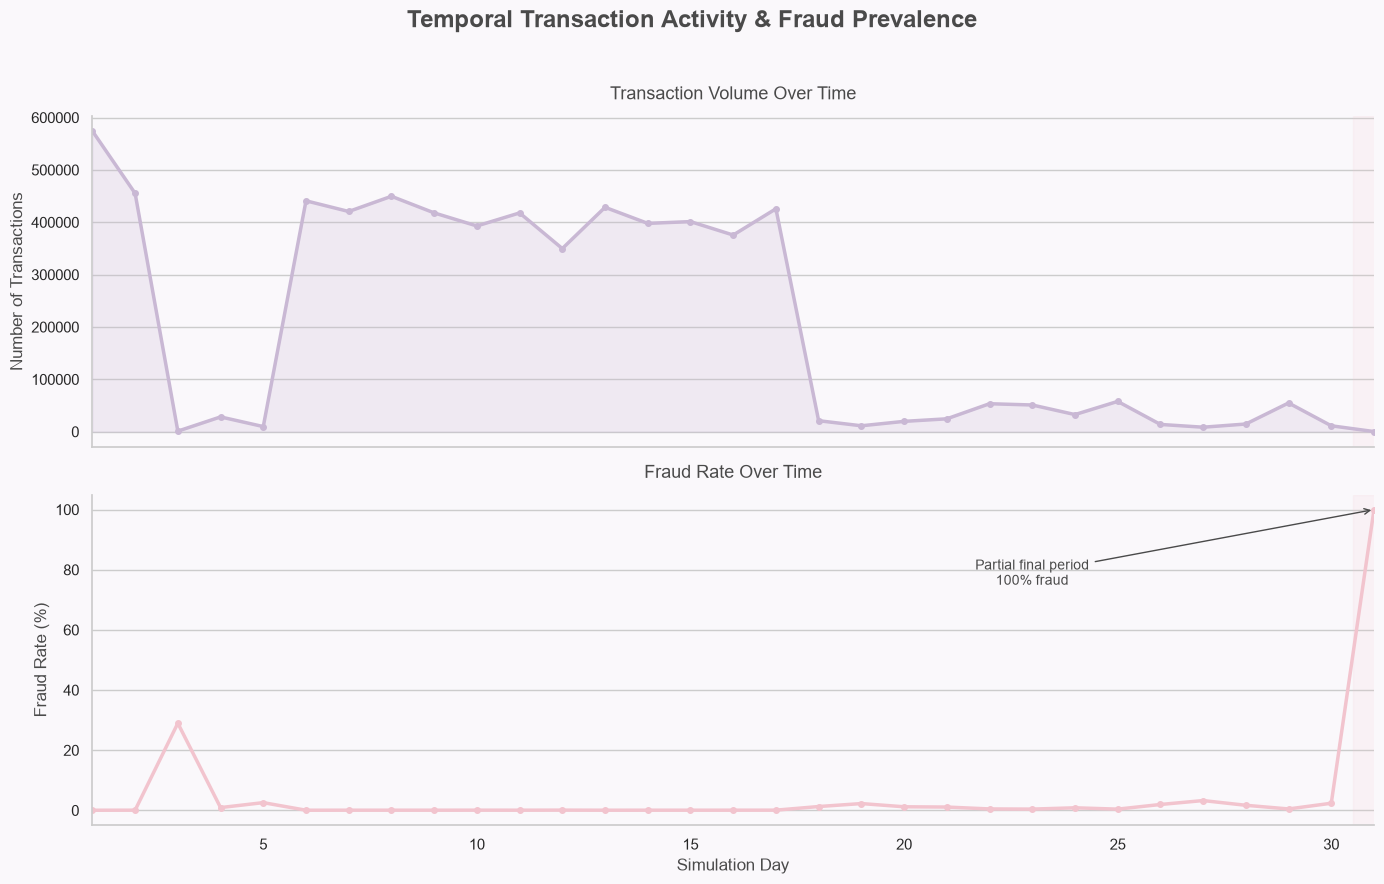

In [32]:

# 5.3 Temporal Fraud Analysis — Visualization

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True,
    facecolor=COLORS["background"]
)

fig.suptitle(
    "Temporal Transaction Activity & Fraud Prevalence",
    fontsize=17,
    fontweight="bold",
    color=COLORS["text"],
    y=0.98
)

days = temporal_summary["Simulation Day"]
volume = temporal_summary["Total Transactions"]
fraud_rate = temporal_summary["Fraud Rate (%)"]

for ax in axes:
    ax.set_facecolor(COLORS["background"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", visible=False)

# 1. Transaction volume
axes[0].plot(
    days,
    volume,
    color=COLORS["lavender"],
    linewidth=2.5,
    marker="o",
    markersize=4
)

axes[0].fill_between(
    days,
    volume,
    color=COLORS["lavender"],
    alpha=0.22
)

axes[0].set_title(
    "Transaction Volume Over Time",
    fontsize=13,
    pad=12
)
axes[0].set_ylabel("Number of Transactions")

# 2. Fraud rate
axes[1].plot(
    days,
    fraud_rate,
    color=COLORS["pink"],
    linewidth=2.5,
    marker="o",
    markersize=4
)

axes[1].set_title(
    "Fraud Rate Over Time",
    fontsize=13,
    pad=12
)
axes[1].set_ylabel("Fraud Rate (%)")
axes[1].set_xlabel("Simulation Day")

# Highlight the partial final period
for ax in axes:
    ax.axvspan(
        30.5, 31.5,
        color=COLORS["pink"],
        alpha=0.12
    )
    ax.set_xlim(1, 31)

axes[1].annotate(
    "Partial final period\n100% fraud",
    xy=(31, 100),
    xytext=(23, 75),
    arrowprops={
        "arrowstyle": "->",
        "color": COLORS["text"]
    },
    fontsize=10,
    color=COLORS["text"],
    ha="center"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


#### Temporal Visualization — Logarithmic Fraud Rate Scale

Fraud rates vary substantially across simulation periods, with extreme values observed during periods of unusually low transaction activity.

A linear percentage scale would compress most observations near zero due to the 100% fraud rate in the final partial period.

To improve readability, the fraud rate is displayed on a logarithmic axis. This allows both low-prevalence periods and extreme spikes to remain visible without modifying the underlying values.

**Note:** The logarithmic scale emphasizes relative differences rather than absolute percentage-point changes. The final simulation period is highlighted separately because it contains only 272 transactions, all labeled as fraudulent.

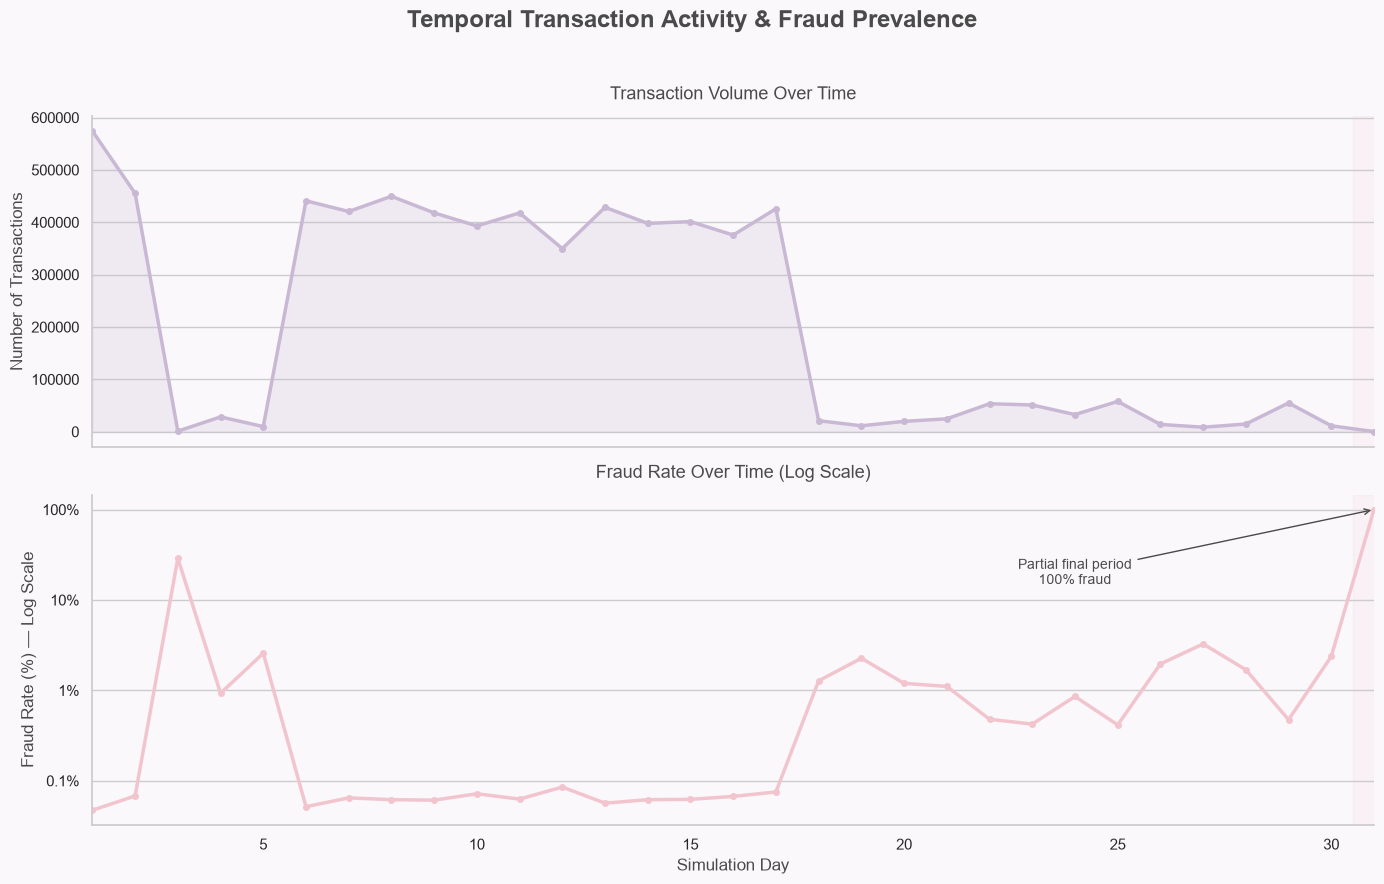

In [35]:

# 5.3 Temporal Fraud Analysis — Improved Visualization

from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True,
    facecolor=COLORS["background"]
)

fig.suptitle(
    "Temporal Transaction Activity & Fraud Prevalence",
    fontsize=17,
    fontweight="bold",
    color=COLORS["text"],
    y=0.98
)

days = temporal_summary["Simulation Day"]
volume = temporal_summary["Total Transactions"]
fraud_rate = temporal_summary["Fraud Rate (%)"]

for ax in axes:
    ax.set_facecolor(COLORS["background"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", visible=False)

# 1. Transaction volume
axes[0].plot(
    days,
    volume,
    color=COLORS["lavender"],
    linewidth=2.5,
    marker="o",
    markersize=4
)

axes[0].fill_between(
    days,
    volume,
    color=COLORS["lavender"],
    alpha=0.22
)

axes[0].set_title(
    "Transaction Volume Over Time",
    fontsize=13,
    pad=12
)
axes[0].set_ylabel("Number of Transactions")

# 2. Fraud rate — logarithmic scale
axes[1].plot(
    days,
    fraud_rate,
    color=COLORS["pink"],
    linewidth=2.5,
    marker="o",
    markersize=4
)

axes[1].set_yscale("log")
axes[1].set_title(
    "Fraud Rate Over Time (Log Scale)",
    fontsize=13,
    pad=12
)
axes[1].set_ylabel("Fraud Rate (%) — Log Scale")
axes[1].set_xlabel("Simulation Day")

# Readable percentage labels
axes[1].yaxis.set_major_formatter(
    FuncFormatter(lambda y, _: f"{y:g}%")
)

# Highlight the partial final period
for ax in axes:
    ax.axvspan(
        30.5, 31.5,
        color=COLORS["pink"],
        alpha=0.12
    )
    ax.set_xlim(1, 31)

axes[1].annotate(
    "Partial final period\n100% fraud",
    xy=(31, 100),
    xytext=(24, 15),
    arrowprops={
        "arrowstyle": "->",
        "color": COLORS["text"]
    },
    fontsize=10,
    color=COLORS["text"],
    ha="center"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


### Findings — Temporal Fraud Analysis

- **Strong temporal variation in transaction volume:** Transaction activity varies substantially across the 31 simulation periods, ranging from hundreds to several hundred thousand transactions per period.

- **Fraud rate volatility:** Fraud prevalence exhibits pronounced fluctuations, including 28.97% on simulation day 3 and 100% on day 31. These extreme rates occur in periods with unusually low transaction volumes.

- **Relatively stable absolute fraud counts:** Most simulation periods contain approximately 200–320 fraudulent transactions, despite large differences in overall transaction activity. This contributes to substantial variation in observed fraud rates.

- **Partial final period:** Simulation day 31 contains only 272 transactions, all labeled as fraudulent. This observation may reflect a boundary effect or simulator-specific behavior rather than a generalizable temporal fraud pattern.

- **Potential temporal distribution shift:** The substantial variation in transaction volume and fraud prevalence suggests that model performance may differ across simulation periods.

**Decisions:**
- Preserve the chronological ordering of transactions during model development.
- Evaluate time-based training, validation, and test splits rather than relying exclusively on random splitting.
- Investigate whether the final simulation periods introduce distribution shifts that could distort model evaluation.
- Avoid interpreting simulation steps as real calendar dates or verified hours of the day.

**Conclusion:** Fraud prevalence varies considerably throughout the simulation, largely alongside changes in transaction volume. These patterns highlight the importance of temporal validation and careful interpretation of simulator-specific behavior.


## 6. Feature Relationships & Correlation Analysis

Understanding relationships between financial variables can reveal structural patterns, potential feature redundancy, and associations with fraudulent activity.

This section examines numerical correlations while distinguishing descriptive relationships from features that would be available at prediction time.

### 6.1 Numerical Correlation Analysis

We calculate the Pearson correlation matrix for the numerical transaction variables and the binary fraud target.

Pearson's correlation coefficient measures the strength and direction of a linear relationship between two variables, ranging from -1 to +1.

The analysis focuses on:

- **Balance relationships:** Associations between pre-transaction and post-transaction account balances.
- **Transaction amount:** Relationships between transaction value and account balances.
- **Fraud associations:** Linear relationships between numerical features and `isFraud`.
- **Potential feature leakage:** Variables whose values may only become available after transaction execution.

The analysis uses the complete dataset to avoid relying on a potentially unrepresentative sample of rare fraudulent events.

**Important:** Correlation does not imply causation or predictive usefulness. Weak linear correlations may coexist with meaningful nonlinear relationships, particularly in highly imbalanced classification problems.


In [36]:

# 6.1 Numerical Correlation Analysis

import duckdb

numerical_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "isFraud"
]

con = duckdb.connect()

# Calculate pairwise Pearson correlations on the full dataset
correlation_expressions = [
    f'corr("{col1}", "{col2}") AS "{col1}__{col2}"'
    for col1 in numerical_features
    for col2 in numerical_features
]

query = f"""
SELECT
    {", ".join(correlation_expressions)}
FROM read_csv_auto(?)
"""

correlation_result = con.execute(
    query,
    [DATA_PATH.resolve().as_posix()]
).df()

con.close()

# Reconstruct the correlation matrix
correlation_matrix = pd.DataFrame(
    index=numerical_features,
    columns=numerical_features,
    dtype=float
)

for col1 in numerical_features:
    for col2 in numerical_features:
        correlation_matrix.loc[col1, col2] = (
            correlation_result.loc[0, f"{col1}__{col2}"]
        )

display(correlation_matrix.round(3))


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
step,1.000,0.022,-0.010,-0.010,0.028,0.026,0.032
amount,0.022,1.000,-0.003,-0.008,0.294,0.459,0.077
oldbalanceOrg,-0.010,-0.003,1.000,0.999,0.066,0.042,0.010
newbalanceOrig,-0.010,-0.008,0.999,1.000,0.068,0.042,-0.008
oldbalanceDest,0.028,0.294,0.066,0.068,1.000,0.977,-0.006
newbalanceDest,0.026,0.459,0.042,0.042,0.977,1.000,0.001
isFraud,0.032,0.077,0.010,-0.008,-0.006,0.001,1.000


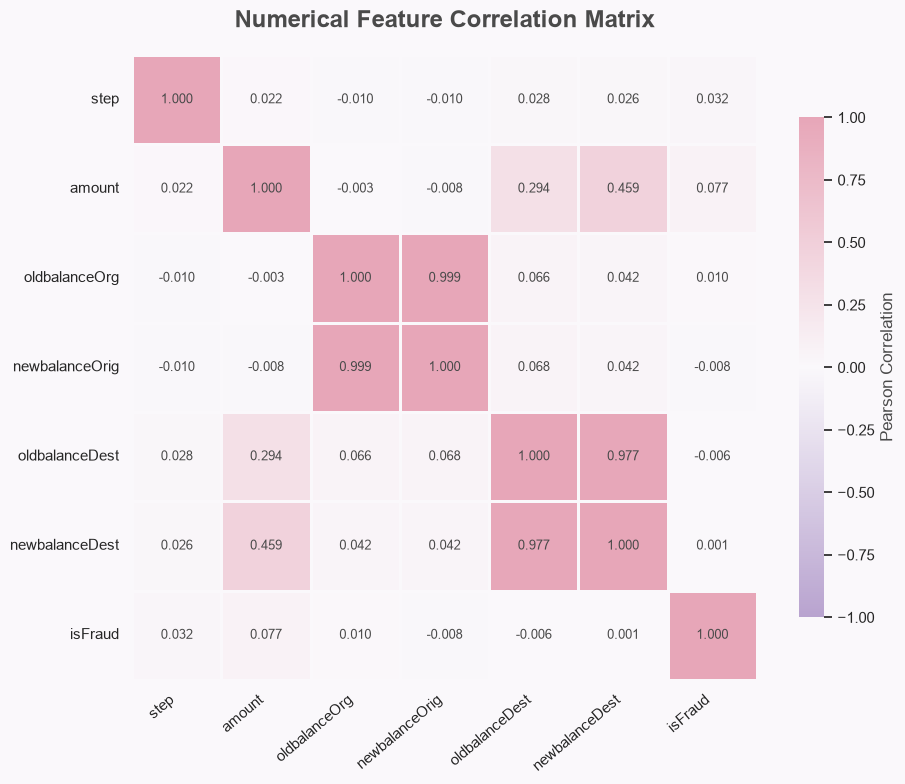

In [41]:


# 6.1 Numerical Correlation Analysis — Heatmap

from matplotlib.colors import LinearSegmentedColormap

# Custom soft diverging palette
soft_diverging = LinearSegmentedColormap.from_list(
    "soft_diverging",
    [
        "#B8A3CF",  # Lavender: negative correlations
        "#FAF8FB",  # Neutral: zero correlation
        "#E7A6B8"   # Pink: positive correlations
    ]
)

# Format annotations without negative zero
heatmap_annotations = correlation_matrix.copy()
heatmap_annotations = heatmap_annotations.mask(
    heatmap_annotations.abs() < 0.0005, 0
)

# Create figure
fig, ax = plt.subplots(
    figsize=(10, 8),
    facecolor=COLORS["background"]
)

# Correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=heatmap_annotations,
    fmt=".3f",
    cmap=soft_diverging,
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=1,
    linecolor=COLORS["background"],
    cbar_kws={
        "label": "Pearson Correlation",
        "shrink": 0.8
    },
    annot_kws={
        "size": 9,
        "color": COLORS["text"]
    },
    ax=ax
)

# Title and labels
ax.set_title(
    "Numerical Feature Correlation Matrix",
    fontsize=17,
    fontweight="bold",
    color=COLORS["text"],
    pad=20
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=40,
    ha="right"
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0
)

ax.set_facecolor(COLORS["background"])

plt.tight_layout()
plt.show()


### Findings — Numerical Correlation Analysis

- **Strong balance correlations:** `oldbalanceOrg` and `newbalanceOrig` exhibit an almost perfect positive correlation (r = 0.999). Similarly, `oldbalanceDest` and `newbalanceDest` are strongly correlated (r = 0.977), reflecting substantial overlap in recorded account balance information.

- **Transaction amount and destination balances:** `amount` shows a moderate positive correlation with `newbalanceDest` (r = 0.459) and a weaker positive correlation with `oldbalanceDest` (r = 0.294).

- **Weak linear associations with fraud:** Among the numerical features analyzed, `amount` has the highest Pearson correlation with `isFraud` (r = 0.077), followed by `step` (r = 0.032). All remaining numerical features exhibit correlations close to zero.

- **Limitations of Pearson correlation:** Weak correlations with the binary fraud target do not imply a lack of predictive information. Fraud detection may depend on nonlinear relationships, feature interactions, and transaction-specific behavior that Pearson correlation cannot capture.

- **Potential feature redundancy and leakage:** Strong correlations between pre- and post-transaction balances highlight overlapping information. Post-transaction balances may also introduce data leakage in a pre-authorization prediction setting.

**Decisions:**
- Retain `amount` and pre-transaction balances as candidate features for further investigation.
- Evaluate nonlinear relationships and interactions during feature engineering.
- Avoid removing features solely because of low Pearson correlation with `isFraud`.
- Exclude post-transaction balance variables from the initial pre-authorization modeling feature set unless their availability at prediction time can be established.

**Conclusion:** The numerical variables exhibit strong relationships among account balances but only weak individual linear associations with fraud. These results support a modeling strategy that considers nonlinear patterns, transaction context, and strict feature availability constraints rather than relying exclusively on correlation-based feature selection.


### 6.2 Rule-Based Fraud Flag Analysis

The PaySim dataset includes `isFlaggedFraud`, an indicator associated with a predefined transaction-monitoring rule.

Unlike `isFraud`, which represents the ground-truth fraud label, `isFlaggedFraud` represents a rule-generated alert.

We evaluate how closely these alerts align with the recorded fraud labels.

The analysis focuses on:

- **Flagged transaction volume:** Number of transactions identified by the rule.
- **Confusion matrix:** True positives, false positives, true negatives, and false negatives.
- **Precision:** Proportion of flagged transactions that are actually fraudulent.
- **Recall:** Proportion of fraudulent transactions detected by the rule.
- **F1-score:** Harmonic mean of precision and recall.

The analysis uses the complete dataset to provide an accurate assessment of the rule's observed performance.

**Objective:** Establish a descriptive rule-based benchmark for comparison with future fraud detection models.

**Important:** This benchmark is evaluated on the available dataset, not on a held-out test set. Any comparison with future models must use the same evaluation population and account for differences in feature availability.


In [42]:

# 6.2 Rule-Based Fraud Flag Analysis

rule_counts = {
    "TN": 0,
    "FP": 0,
    "FN": 0,
    "TP": 0
}

flagged_by_type = {}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["type", "isFraud", "isFlaggedFraud"],
    chunksize=250_000
):
    actual = chunk["isFraud"]
    flagged = chunk["isFlaggedFraud"]

    rule_counts["TN"] += (
        (actual == 0) & (flagged == 0)
    ).sum()

    rule_counts["FP"] += (
        (actual == 0) & (flagged == 1)
    ).sum()

    rule_counts["FN"] += (
        (actual == 1) & (flagged == 0)
    ).sum()

    rule_counts["TP"] += (
        (actual == 1) & (flagged == 1)
    ).sum()

    type_counts = (
        chunk.loc[flagged == 1, "type"]
        .value_counts()
    )

    for transaction_type, count in type_counts.items():
        flagged_by_type[transaction_type] = (
            flagged_by_type.get(transaction_type, 0)
            + int(count)
        )

tn = int(rule_counts["TN"])
fp = int(rule_counts["FP"])
fn = int(rule_counts["FN"])
tp = int(rule_counts["TP"])

precision = tp / (tp + fp) if (tp + fp) else 0
recall = tp / (tp + fn) if (tp + fn) else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) else 0
)

rule_summary = pd.DataFrame({
    "Metric": [
        "Total Flagged Transactions",
        "True Positives",
        "False Positives",
        "False Negatives",
        "True Negatives",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Value": [
        tp + fp,
        tp,
        fp,
        fn,
        tn,
        round(precision, 6),
        round(recall, 6),
        round(f1, 6)
    ]
})

display(rule_summary)

print("Flagged transactions by type:")
display(
    pd.Series(
        flagged_by_type,
        name="Flagged Transactions"
    ).sort_values(ascending=False)
)

assert tn + fp + fn + tp == total_rows
assert tp + fn == 8_213


,Metric,Value
0,Total Flagged Transactions,1.600000e+01
1,True Positives,1.600000e+01
2,False Positives,0.000000e+00
3,False Negatives,8.197000e+03
4,True Negatives,6.354407e+06
5,Precision,1.000000e+00
6,Recall,1.948000e-03
7,F1-Score,3.889000e-03


Flagged transactions by type:


TRANSFER    16
Name: Flagged Transactions, dtype: int64

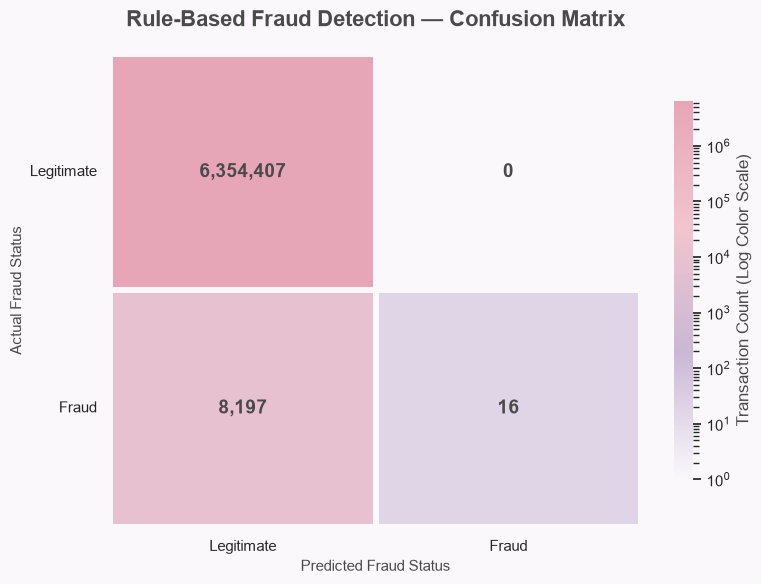

In [44]:

# 6.2 Rule-Based Fraud Detection — Confusion Matrix

from matplotlib.colors import LogNorm, LinearSegmentedColormap
from matplotlib.ticker import LogLocator, NullLocator

colorbar = ax.collections[0].colorbar
colorbar.locator = LogLocator(base=10, numticks=7)
colorbar.ax.yaxis.set_minor_locator(NullLocator())
colorbar.update_ticks()

confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])

# Soft lavender-to-pink palette
confusion_cmap = LinearSegmentedColormap.from_list(
    "soft_confusion",
    [
        "#FAF8FB",
        "#C9B8D4",
        "#F2C4CE",
        "#E7A6B8"
    ]
)

fig, ax = plt.subplots(
    figsize=(8, 6),
    facecolor=COLORS["background"]
)

# Add 1 for logarithmic color scaling only
sns.heatmap(
    confusion_matrix + 1,
    annot=np.array([
        [f"{tn:,}", f"{fp:,}"],
        [f"{fn:,}", f"{tp:,}"]
    ]),
    fmt="",
    cmap=confusion_cmap,
    norm=LogNorm(
        vmin=1,
        vmax=confusion_matrix.max() + 1
    ),
    linewidths=3,
    linecolor=COLORS["background"],
    cbar_kws={
        "label": "Transaction Count (Log Color Scale)",
        "shrink": 0.8
    },
    annot_kws={
        "size": 14,
        "weight": "bold",
        "color": COLORS["text"]
    },
    ax=ax
)

ax.set_title(
    "Rule-Based Fraud Detection — Confusion Matrix",
    fontsize=16,
    fontweight="bold",
    color=COLORS["text"],
    pad=20
)

ax.set_xlabel("Predicted Fraud Status", fontsize=11)
ax.set_ylabel("Actual Fraud Status", fontsize=11)

ax.set_xticklabels(
    ["Legitimate", "Fraud"],
    rotation=0
)

ax.set_yticklabels(
    ["Legitimate", "Fraud"],
    rotation=0
)

ax.set_facecolor(COLORS["background"])

plt.tight_layout()
plt.show()


### Findings — Rule-Based Fraud Flag Analysis

- **Extremely limited fraud detection:** The rule flags only 16 transactions out of 6,362,620, all of which are labeled as fraudulent. All flagged transactions belong to the `TRANSFER` category.

- **Perfect observed precision:** The rule achieves 100% precision, with 16 true positives and no false positives. However, this result is based on a very small number of flagged transactions and should not be interpreted as evidence of perfect generalization.

- **Exceptionally low recall:** Only 16 of the 8,213 fraudulent transactions are detected, resulting in a recall of approximately **0.195%**. The remaining **8,197 fraudulent transactions (99.805%)** are not flagged.

- **Poor overall detection effectiveness:** The F1-score is approximately 0.0039, reflecting the substantial imbalance between perfect observed precision and extremely low recall.

- **Limited rule coverage:** The rule generates alerts exclusively for `TRANSFER` transactions and does not identify any fraudulent `CASH_OUT` transactions in the dataset.

**Decisions:**
- Use the rule as a descriptive benchmark for future fraud detection models.
- Prioritize recall and precision-recall trade-offs when evaluating FinGuard AI.
- Compare future models and the rule on the same held-out evaluation set.
- Investigate whether `isFlaggedFraud` is available at prediction time before considering it as a model feature.

**Conclusion:** The existing rule is highly selective but fails to identify nearly all recorded fraud cases. These findings motivate the development of a more comprehensive fraud detection approach capable of improving recall while maintaining an acceptable false positive rate.


## 7. EDA Conclusions & Modeling Decisions

This exploratory analysis examined the complete PaySim dataset, comprising **6,362,620 synthetic financial transactions**, to identify fraud patterns, assess data quality, and establish a foundation for the FinGuard AI modeling pipeline.

The findings highlight the challenges of extreme class imbalance, transaction-specific fraud behavior, simulator-dependent balance patterns, and the limitations of rule-based detection.

### 7.1 Key Findings

**1. Extreme Class Imbalance**

Only **8,213 transactions (0.1291%)** are fraudulent. A classifier predicting every transaction as legitimate would achieve approximately 99.87% accuracy while detecting no fraud.

This makes accuracy unsuitable as a primary evaluation metric.

**2. Data Quality and Balance Integrity**

No explicit missing values or exact duplicate records were identified.

However, substantial accounting discrepancies were observed, particularly for `TRANSFER` and `CASH_OUT` transactions.

Further analysis revealed a strong association between these discrepancies and zero ending origin balances. These patterns may reflect simulator-specific conventions and should not be automatically classified as data errors.

**3. Fraud Concentration by Transaction Type**

All recorded fraud cases occur in two transaction categories:

- `TRANSFER`: 4,097 fraudulent transactions; fraud rate of 0.7688%.
- `CASH_OUT`: 4,116 fraudulent transactions; fraud rate of 0.1840%.

No fraud cases are labeled in `PAYMENT`, `CASH_IN`, or `DEBIT`.

Transaction type is therefore an important candidate feature, although these patterns may not generalize beyond PaySim.

**4. Transaction Amount Patterns**

Fraudulent `CASH_OUT` transactions have a median amount approximately 2.96 times that of legitimate cash-out transactions.

In contrast, fraudulent and legitimate `TRANSFER` transactions exhibit similar medians and substantial distributional overlap.

This suggests that transaction amount should be interpreted jointly with transaction type rather than used as a standalone fraud indicator.

**5. Temporal Distribution Shifts**

Transaction volume and fraud prevalence vary substantially throughout the simulation.

Several periods exhibit unusually low transaction activity and elevated fraud rates. The final partial simulation period contains 272 transactions, all labeled as fraudulent.

These observations highlight potential simulator-specific temporal effects and the importance of chronological model evaluation.

**6. Numerical Feature Relationships**

Strong correlations exist between pre- and post-transaction balances:

- `oldbalanceOrg` and `newbalanceOrig`: r = 0.999.
- `oldbalanceDest` and `newbalanceDest`: r = 0.977.

Individual numerical correlations with `isFraud` are weak, with `amount` showing the strongest observed linear association (r = 0.077).

This supports investigating nonlinear relationships and feature interactions rather than relying exclusively on correlation-based feature selection.

**7. Rule-Based Detection Limitations**

The existing `isFlaggedFraud` indicator identifies only 16 of the 8,213 fraudulent transactions.

Its observed performance is:

- Precision: 100%.
- Recall: approximately 0.195%.
- F1-score: approximately 0.0039.

Although the rule produces no false positives in this dataset, it misses 8,197 fraudulent transactions.

This provides a descriptive benchmark and motivates the development of a more comprehensive fraud detection approach.

### 7.2 Feature Selection & Leakage Prevention

For the initial modeling pipeline, FinGuard AI will target **pre-transaction fraud detection**, where predictions must be generated using information available before transaction execution.

| Feature | Initial Decision | Rationale |
|---|---|---|
| `step` | Retain | Simulation time; useful for chronological ordering and temporal context |
| `type` | Retain | Strong transaction-specific differences in fraud prevalence |
| `amount` | Retain | Potentially informative, particularly when combined with transaction type |
| `oldbalanceOrg` | Retain conditionally | Pre-transaction balance; availability must be verified |
| `oldbalanceDest` | Retain conditionally | Pre-transaction destination balance; availability and zero-value conventions require validation |
| `newbalanceOrig` | Exclude | Post-transaction information; potential data leakage |
| `newbalanceDest` | Exclude | Post-transaction information; potential data leakage |
| `nameOrig` | Retain for feature engineering | Candidate for account-level and graph-based behavioral features |
| `nameDest` | Retain for feature engineering | Candidate for recipient-level and graph-based features |
| `isFlaggedFraud` | Exclude from initial model | Existing rule-generated signal; availability and independence require assessment |
| `isFraud` | Target | Binary fraud label; never used as a predictor |

Account identifiers will not automatically be treated as ordinary categorical variables. Any account-level features must be constructed using information available at the prediction timestamp.

### 7.3 Preprocessing & Modeling Strategy

Based on the exploratory findings, the following decisions will guide subsequent development:

1. **Preserve original data integrity:** Do not automatically remove zero balances, modify inconsistent records, or discard extreme transaction amounts.

2. **Prevent temporal leakage:** Establish chronological training, validation, and test splits before fitting preprocessing transformations or performing feature selection.

3. **Handle class imbalance:** Evaluate class-weighted models and, where appropriate, resampling strategies applied exclusively to training data.

4. **Engineer transaction-aware features:** Investigate amount transformations, transaction-type interactions, and balance-relative indicators using only information available before transaction execution.

5. **Explore account-level behavior:** Develop historical transaction frequency, monetary activity, and network features without incorporating future transactions.

6. **Establish robust baselines:** Compare simple statistical and machine learning models against the existing rule-based indicator on the same held-out evaluation set.

7. **Use appropriate evaluation metrics:** Prioritize PR-AUC (Average Precision), precision, recall, and F1-score. Include threshold analysis and false-alert burden to reflect operational trade-offs.

8. **Assess temporal robustness:** Investigate performance across simulation periods, particularly where transaction volumes and fraud prevalence differ substantially.

### 7.4 Limitations

PaySim is a synthetic dataset and may not fully represent real-world financial systems.

Its transaction types, balance conventions, fraud mechanisms, and temporal patterns may reflect assumptions embedded in the simulation process.

Furthermore, statistical associations identified during EDA do not establish causal relationships or guarantee predictive performance on unseen data.

Model evaluation must therefore distinguish performance within PaySim from claims about real-world deployment readiness.

### 7.5 Next Steps

The next stage of FinGuard AI will focus on building a reproducible, leakage-aware machine learning pipeline.

Planned activities include:

- Defining the prediction-time feature contract.
- Creating chronological training, validation, and test datasets.
- Implementing preprocessing and feature engineering.
- Training baseline fraud detection models.
- Evaluating performance against the rule-based benchmark.
- Exploring explainability, behavioral features, and graph-based fraud detection.

### Final Conclusion

The exploratory analysis demonstrates that fraud detection in PaySim is a highly imbalanced classification problem characterized by transaction-specific patterns, substantial temporal variation, and limitations in existing rule-based detection.

The findings provide a clear foundation for developing FinGuard AI as a reproducible and explainable fraud detection system.

**The next challenge is to determine whether machine learning can detect substantially more fraudulent transactions while maintaining an operationally acceptable false positive rate.**
